# Task 2: Multivariable Linear Regression
Predicting customer purchase amount (in dollars) from demographic and
product attributes, using the Black Friday retail transactions dataset.

**Approach:** seven predictors (gender, age, occupation, marital status,
product category, and two city-category dummy variables) were selected
after testing an eighth variable (length of residence in current city)
and removing it for lacking statistical significance (p = 0.124).

## Libraries
pandas/numpy handle data loading and manipulation, statsmodels provides
the regression with full statistical inference (p-values, R-squared,
coefficient significance), and scikit-learn is used for the train/test
split and error metrics (MAE, RMSE) to evaluate predictions on unseen data.

In [85]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt

## Load and Inspect the Data

In [86]:
df = pd.read_csv('train.csv')
df.head()

,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Product_Category_2,Product_Category_3,Purchase
0,1000001,P00069042,F,0-17,10,A,2,0,3,NaN,NaN,8370
1,1000001,P00248942,F,0-17,10,A,2,0,1,6.0,14.0,15200
2,1000001,P00087842,F,0-17,10,A,2,0,12,NaN,NaN,1422
3,1000001,P00085442,F,0-17,10,A,2,0,12,14.0,NaN,1057
4,1000002,P00285442,M,55+,16,C,4+,0,8,NaN,NaN,7969


In [87]:
# Check for missing values before selecting predictors.
# Product_Category_2 and Product_Category_3 are expected to have gaps,
# since not every product is tagged with a secondary/tertiary category.
df.isnull().sum()


,0
User_ID,0
Product_ID,0
Gender,0
Age,0
Occupation,0
City_Category,0
Stay_In_Current_City_Years,0
Marital_Status,0
Product_Category_1,0
Product_Category_2,173638


count    550068.000000
mean       9263.968713
std        5023.065394
min          12.000000
25%        5823.000000
50%        8047.000000
75%       12054.000000
max       23961.000000
Name: Purchase, dtype: float64

IQR Upper Bound: $21,400.50
Outliers above threshold: 2,677 (0.49%)


<Axes: title={'center': 'Pre-Cleaning Purchase Distribution & Outlier Inspection'}>

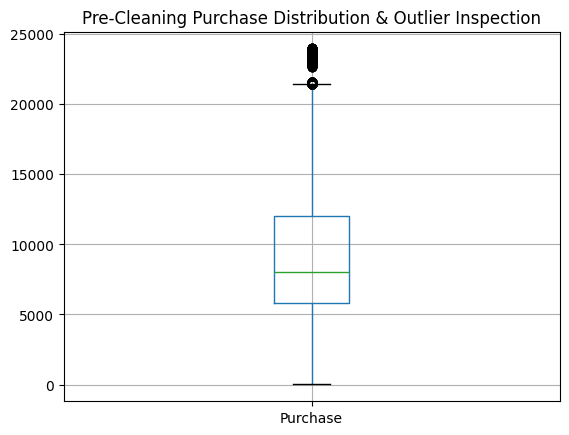

In [88]:
# Summary statistics (min, max, quartiles)
print(df['Purchase'].describe())

# IQR outlier threshold & count
q1, q3 = df['Purchase'].quantile([0.25, 0.75])
upper_bound = q3 + 1.5 * (q3 - q1)

outliers = df['Purchase'] > upper_bound
print(f"\nIQR Upper Bound: ${upper_bound:,.2f}")
print(f"Outliers above threshold: {outliers.sum():,} ({outliers.mean():.2%})")

# Boxplot visualization
plt.title('Pre-Cleaning Purchase Distribution & Outlier Inspection')
df.boxplot(column='Purchase')

### Interpretation
The Purchase column contains no negative values, zero values, or other
signs of data entry errors, the minimum (\$12) and maximum (\$23,961) are
both plausible individual transaction amounts. Using the standard IQR
method, approximately 0.49% of transactions fall above the upper bound
and would technically be flagged as statistical outliers.

However, these
represent genuine high-value purchases rather than corrupted data. Since
Black Friday shopping behaviour naturally includes a small number of
larger transactions, removing these rows would not be correcting an
error, it would mean deleting valid customer data specifically because
it is harder for a linear model to fit, which would make the model's
reported accuracy artificially better without making it more truthful.
For this reason, no outliers were removed from the dataset.



## Data Cleaning

In [89]:
# Product_Category_2 (~31.6% missing) and Product_Category_3 (~69.7% missing)
# are category codes, not continuous values, so imputing them with a mean
# or median wouldn't be meaningful. They are dropped rather than imputed.
# Product_Category_1 has no missing values and is used as the category predictor.
df = df.drop(columns=['Product_Category_2', 'Product_Category_3'])

## Encoding Categorical Variables
Two encoding techniques are used, as specified for this assessment: label
encoding for Gender and Age (ordinal/binary categories where a single
numeric code per category is appropriate), and one-hot encoding for
City_Category (a non-ordinal category with three values, where dummy
variables avoid implying a false order between A, B, and C).

In [90]:
from sklearn.preprocessing import LabelEncoder

# Label encoding: Gender (binary category, F/M -> 0/1)
gender_encoder = LabelEncoder()
df['Gender'] = gender_encoder.fit_transform(df['Gender'])
print('Gender classes:', list(gender_encoder.classes_))  # ['F', 'M'] -> 0, 1

# Label encoding: Age brackets.
# Note: LabelEncoder always assigns codes based on alphabetical/lexicographic
# sort order of the category strings (via np.unique), it does not preserve
# any custom order passed to it. For this dataset the age bracket strings
# ('0-17', '18-25', '26-35', ...) happen to sort alphabetically in the same
# order as their numeric/life-stage order, so the codes come out correct,
# but this was verified rather than assumed before relying on it.
age_encoder = LabelEncoder()
df['Age_Encoded'] = age_encoder.fit_transform(df['Age'])
print('Age classes (in the order LabelEncoder assigned):', list(age_encoder.classes_))

# One-hot encoding: City_Category (three non-ordinal categories, A/B/C).
# drop_first=True avoids the dummy variable trap by using City A as the
# implicit reference category.
city_dummies = pd.get_dummies(df['City_Category'], prefix='City', drop_first=True)
df = pd.concat([df, city_dummies], axis=1)

df.head()

Gender classes: ['F', 'M']
Age classes (in the order LabelEncoder assigned): ['0-17', '18-25', '26-35', '36-45', '46-50', '51-55', '55+']


,User_ID,Product_ID,Gender,Age,Occupation,City_Category,Stay_In_Current_City_Years,Marital_Status,Product_Category_1,Purchase,Age_Encoded,City_B,City_C
0,1000001,P00069042,0,0-17,10,A,2,0,3,8370,0,False,False
1,1000001,P00248942,0,0-17,10,A,2,0,1,15200,0,False,False
2,1000001,P00087842,0,0-17,10,A,2,0,12,1422,0,False,False
3,1000001,P00085442,0,0-17,10,A,2,0,12,1057,0,False,False
4,1000002,P00285442,1,55+,16,C,4+,0,8,7969,6,False,True


## Feature Matrix

In [91]:
# Seven predictors selected based on the assessment brief's demographic
# and product variables. Stay_In_Current_City_Years was tested separately
# and excluded after returning p = 0.124 (not significant at 0.05).
feature_cols = [
    'Gender', 'Age_Encoded', 'Occupation', 'Marital_Status',
    'Product_Category_1', 'City_B', 'City_C'
]

X = df[feature_cols].astype(float)
y = df['Purchase'].astype(float)

X.shape, y.shape

((550068, 7), (550068,))

## Train/Test Split
An 80/20 split is used so the model can be evaluated on data it has not
seen during fitting. A fixed random_state makes the split reproducible.

In [92]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

X_train.shape, X_test.shape

((440054, 7), (110014, 7))

## Fit the Regression Model
statsmodels' OLS is used instead of scikit-learn's LinearRegression because
it reports p-values, standard errors, and R-squared directly, which are
needed to judge whether the model is statistically sound, not just whether
it produces predictions.

In [93]:
X_train_sm = sm.add_constant(X_train)
model = sm.OLS(y_train, X_train_sm).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:               Purchase   R-squared:                       0.125
Model:                            OLS   Adj. R-squared:                  0.125
Method:                 Least Squares   F-statistic:                     8976.
Date:                Thu, 10 Sep 2026   Prob (F-statistic):               0.00
Time:                        03:52:48   Log-Likelihood:            -4.3453e+06
No. Observations:              440054   AIC:                         8.691e+06
Df Residuals:                  440046   BIC:                         8.691e+06
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
const               1.065e+04     25

### Interpreting the Model Summary
Check two things in the output above before trusting the model:
1. **R-squared** — the proportion of variance in Purchase explained by
   these seven predictors. A modest value here is expected, since consumer
   spending is driven by many factors beyond demographics and category.
2. **P>|t| column** — every predictor should show p < 0.05. If any
   predictor doesn't, it is not contributing reliably and should be
   reconsidered (this is exactly why Stay_In_Current_City_Years was
   dropped earlier, at p = 0.124).

## Evaluate on the Test Set

In [94]:
X_test_sm = sm.add_constant(X_test)
y_pred = model.predict(X_test_sm)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"R-squared: {r2:.4f}")
print(f"MAE:  ${mae:,.2f}")
print(f"RMSE: ${rmse:,.2f}")

R-squared: 0.1238
MAE:  $3,594.97
RMSE: $4,692.06


## Residual Diagnostics
Residual plots reveal whether the linear model's assumptions hold. Random
scatter around zero (left plot) and a single smooth peak (right plot)
would indicate a good linear fit; patterns in either suggest the true
relationship is not fully linear.

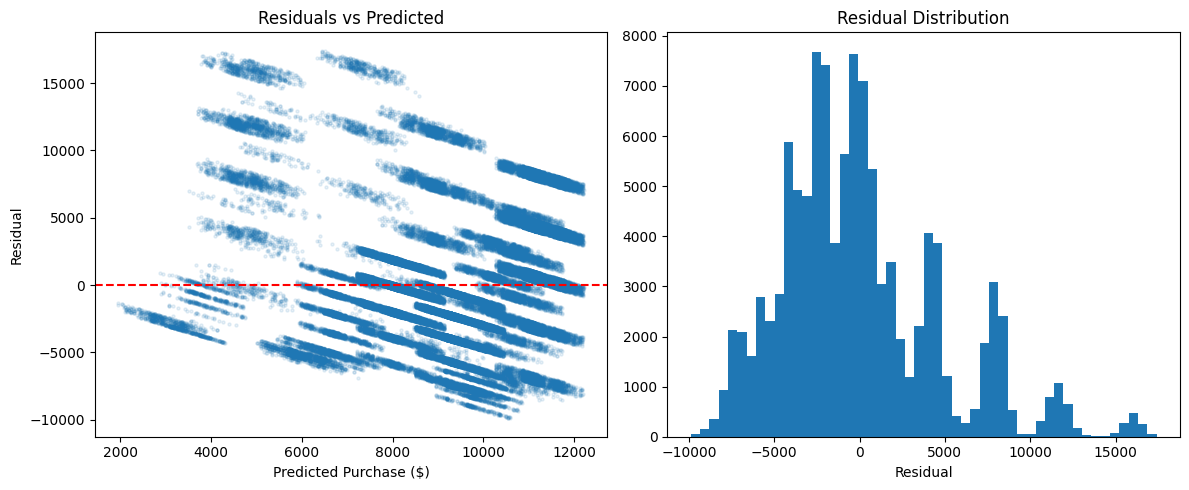

In [95]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(y_pred, residuals, alpha=0.1, s=5)
axes[0].axhline(0, color='red', linestyle='--')
axes[0].set_xlabel('Predicted Purchase ($)')
axes[0].set_ylabel('Residual')
axes[0].set_title('Residuals vs Predicted')

axes[1].hist(residuals, bins=50)
axes[1].set_xlabel('Residual')
axes[1].set_title('Residual Distribution')


plt.tight_layout()
plt.savefig('residual_diagnostics.png', dpi=150)
plt.show()

### Interpreting the Residual Plots
Diagonal banding in the residuals-vs-predicted plot, and a multi-modal
(multi-peaked) residual distribution, both indicate the relationship
between these predictors and Purchase is not fully linear — likely
because different product categories carry systematically different
price points that a single linear coefficient cannot capture. This does
not invalidate the model; it means predictions should be treated as
directional (useful for comparing segments) rather than exact.

## Predict Purchase for a New Customer

In [96]:
# Example: a new male customer, in the 26-35 age bracket, occupation
# code 4, unmarried, browsing a Product_Category_1 = 1 item, in City B.
new_customer = pd.DataFrame({
    'Gender': [1],
    'Age_Encoded': [2],
    'Occupation': [4],
    'Marital_Status': [0],
    'Product_Category_1': [1],
    'City_B': [1],
    'City_C': [0],
})

new_customer_sm = sm.add_constant(new_customer, has_constant='add')
new_customer_sm = new_customer_sm[X_train_sm.columns]  # match column order

predicted_purchase = model.predict(new_customer_sm)
print(f"Predicted purchase: ${predicted_purchase.iloc[0]:,.2f}")

Predicted purchase: $11,143.83


## Export Coefficient Table for the Written Report

In [97]:
coef_table = pd.DataFrame({
    'coefficient': model.params,
    'std_err': model.bse,
    't_stat': model.tvalues,
    'p_value': model.pvalues,
    'significant_at_0.05': model.pvalues < 0.05
})

coef_table.to_csv('coefficient_significance.csv')
coef_table.round(4)

,coefficient,std_err,t_stat,p_value,significant_at_0.05
const,10653.1599,25.0199,425.7883,0.0000,True
Gender,514.1424,16.5832,31.0039,0.0000,True
Age_Encoded,113.7112,5.5808,20.3753,0.0000,True
Occupation,6.2260,1.0995,5.6625,0.0000,True
Marital_Status,-54.9359,15.1737,-3.6205,0.0003,True
Product_Category_1,-438.0691,1.8060,-242.5686,0.0000,True
City_B,162.2718,17.5347,9.2543,0.0000,True
City_C,686.1268,18.8065,36.4834,0.0000,True


## Generate Predictions for the Provided test.csv
The dataset also includes a separate `test.csv` (233,599 rows) provided
alongside `train.csv`. Unlike `train.csv`, it has no Purchase column, so
it cannot be used to calculate R-squared, MAE, or RMSE — there is no
ground truth to compare predictions against. It can, however, be used to
generate an actual predicted purchase amount for each row, demonstrating
that the model generalises to genuinely new, unseen customer records.

The same fitted encoders (`gender_encoder`, `age_encoder`) from the
training step are reused here via `.transform()`, not `.fit_transform()`,
so that category codes stay exactly consistent with what the model was
trained on.

In [98]:
# Load the provided test set
test_df = pd.read_csv('test.csv')
print(test_df.shape)
test_df.isnull().sum()[['Gender', 'Age', 'Occupation', 'City_Category',
                          'Marital_Status', 'Product_Category_1']]

(233599, 11)


,0
Gender,0
Age,0
Occupation,0
City_Category,0
Marital_Status,0
Product_Category_1,0


In [99]:
# Apply the SAME fitted encoders used on the training data.
# .transform() (not .fit_transform()) ensures category codes match
# exactly what the model was trained on.
test_df['Gender'] = gender_encoder.transform(test_df['Gender'])
test_df['Age_Encoded'] = age_encoder.transform(test_df['Age'])

test_city_dummies = pd.get_dummies(test_df['City_Category'], prefix='City', drop_first=True)
test_df = pd.concat([test_df, test_city_dummies], axis=1)

# Safety check: ensure both dummy columns exist even if a category
# happened to be entirely absent from this file.
for col in ['City_B', 'City_C']:
    if col not in test_df.columns:
        test_df[col] = 0

X_new = test_df[feature_cols].astype(float)
X_new.shape

(233599, 7)

In [100]:
# Generate predictions using the trained model
X_new_sm = sm.add_constant(X_new, has_constant='add')
X_new_sm = X_new_sm[X_train_sm.columns]  # match training column order exactly

test_predictions = model.predict(X_new_sm)

print(f"Generated {len(test_predictions)} predictions")
print(f"Predicted purchase range: ${test_predictions.min():,.2f} - ${test_predictions.max():,.2f}")
print(f"Mean predicted purchase: ${test_predictions.mean():,.2f}")

Generated 233599 predictions
Predicted purchase range: $2,830.18 - $12,222.15
Mean predicted purchase: $9,321.81


In [101]:
# Save predictions alongside the original identifying columns
output = test_df[['User_ID', 'Product_ID']].copy()
output['Predicted_Purchase'] = test_predictions.round(2)
output.to_csv('test_predictions.csv', index=False)
output.head(10)

,User_ID,Product_ID,Predicted_Purchase
0,1000004,P00128942,11335.00
1,1000009,P00113442,10872.49
2,1000010,P00288442,8917.51
3,1000010,P00145342,9355.58
4,1000011,P00053842,9820.66
5,1000013,P00350442,11383.43
6,1000013,P00155442,11821.49
7,1000013,P0094542,11383.43
8,1000015,P00161842,7057.62
9,1000022,P00067942,9184.06


### Note on this output
These predictions cannot be scored for accuracy, since `test.csv` has no
actual Purchase values to compare against. This step demonstrates that
the trained model generalises to new, unseen customer records and
produces plausible purchase estimates, not that those specific estimates
are individually verified correct. The model's real, scored accuracy
(R-squared, MAE, RMSE) comes from the `train.csv` 80/20 split evaluated
earlier in this notebook.

## Summary
The final model uses seven statistically significant predictors
(Gender, Age, Occupation, Marital Status, Product Category, and two
City Category dummies). Model performance and coefficient values are
carried into the Task 3 written report, where they are interpreted in
terms of business decisions rather than statistical output alone. A
supplementary predictions file (`test_predictions.csv`) was also
generated for the provided test set to demonstrate the model's
application to new, unseen customer records.